# Kerr with a thin disk: extra checks

Moved from section 5 of `01-Theoretical-Validations.ipynb` on 2026-10-26. Same setup cells.


In [1]:
!pip install -Uq relatipy kerrgeopy pygro setuptools cython

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try 'pacman -S
    python-xyz', where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Arch-packaged Python package,
    create a virtual environment using 'python -m venv path/to/venv'.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip.
    
    If you wish to install a non-Arch packaged Python application,
    it may be easiest to use 'pipx install xyz', which will manage a
    virtual environment for you. Make sure you have python-pipx
    installed via pacman.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detailed specification.


In [1]:
import dataclasses
import logging
import time
from functools import partial
from pathlib import Path

import relatipy as rp
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
import astropy.constants as const
from astropy.table import Table
from scipy.integrate import quad
from scipy.optimize import brentq
import mpmath as mp

import kerrgeopy as kg
import pygro

Shared helpers:

* `time_scale`: time unit $GM/c^3$, to convert times and velocities given in units of $M$
* `equatorial_orbit`: builds an orbit on $\theta=\pi/2$ from $(u^t,u^r,u^\phi)$, converting to $v^i=u^i/u^t$
* `upward_crossings`: instants where a sampled quantity crosses zero upwards (pericentres, oscillation midpoints). A cubic fit of $y(g)$ through the four samples around each sign change; a linear interpolation limits the error to $\sim10^{-5}$
* `hermite_pericentres`: pericentres from cubic Hermite interpolants that use the stored velocities (see section 3)
* `glue_panels`: panels that share an axis touch, without a gap; call it after plotting. It freezes the layout and moves the axes by hand, and hides a tick label that would cross a joint
* `stacked_blocks`: single-column figure with blocks of panels stacked vertically, (a) on top of (b); panels share $x$ inside each block
* `save_paper_figure`: saves pdf and png of a figure into the preprint folder `figures/<section>/` (skipped if that folder is not next to this repository)

In [2]:
def time_scale(bh):
    """Time unit G M / c^3 of the native geometric convention."""
    return (bh.r_g / const.c).to(u.s)


def equatorial_orbit(bh, r, u_t, u_r, u_phi):
    """Orbit at radius r [M] on the equator, from its four-velocity (u^t, u^r, u^phi) in units of M."""
    return bh.orbit(
        R=r * bh.r_g,
        Theta=90 * u.deg,
        Phi=0 * u.rad,
        vR=u_r / u_t * bh.r_g / time_scale(bh),
        vPhi=u_phi / u_t * u.rad / time_scale(bh),
    )


def upward_crossings(g, y):
    """y where g changes sign from negative to positive, from a cubic fit of y(g) over the four samples around each change."""
    steps = np.where((g[:-1] < 0) & (g[1:] >= 0))[0]
    steps = steps[(steps > 0) & (steps < g.size - 2)]
    return np.array([np.polyval(np.polyfit(g[i-1:i+3], y[i-1:i+3], 3), 0) for i in steps])


def hermite_pericentres(tau, r, u_r, phi, u_phi):
    """Unwrapped phi [rad] at every pericentre, from cubic Hermite interpolants of r(tau) and phi(tau)."""
    phi = np.unwrap(phi)
    phases = []
    for i in np.where((u_r[:-1] < 0) & (u_r[1:] >= 0))[0]:
        h = tau[i+1] - tau[i]
        # r(s) on s in [0, 1]: cubic through r and h*u^r at both ends
        c3 = 2*r[i] - 2*r[i+1] + h*(u_r[i] + u_r[i+1])
        c2 = -3*r[i] + 3*r[i+1] - h*(2*u_r[i] + u_r[i+1])
        roots = np.roots([3*c3, 2*c2, h*u_r[i]])
        s = next(x.real for x in roots
                 if abs(x.imag) < 1e-12 and -1e-9 <= x.real <= 1 + 1e-9 and 6*c3*x.real + 2*c2 > 0)
        phases.append(
            (2*s**3 - 3*s**2 + 1) * phi[i]
            + (s**3 - 2*s**2 + s) * h * u_phi[i]
            + (-2*s**3 + 3*s**2) * phi[i+1]
            + (s**3 - s**2) * h * u_phi[i+1]
        )
    return np.array(phases)


def glue_panels(fig, groups=None):
    """Make panels that share an axis touch. Call after plotting, before saving.

    groups: lists of axes stacked top to bottom that must touch; by default, every column.
    """
    fig.align_ylabels()
    fig.canvas.draw()                  # let the layout engine place labels and legends
    fig.set_layout_engine("none")      # freeze it, then close the gaps by hand
    if groups is None:
        columns = {}
        for ax in fig.axes:
            spec = ax.get_subplotspec()
            if spec is not None and ax.get_visible():
                columns.setdefault(spec.colspan.start, []).append(ax)
        groups = list(columns.values())
    groups = [sorted(group, key=lambda ax: -ax.get_position().y1) for group in groups]
    for axes in groups:
        boxes = [ax.get_position() for ax in axes]
        top, bottom = boxes[0].y1, boxes[-1].y0
        scale = (top - bottom) / sum(box.height for box in boxes)
        for ax, box in zip(axes, boxes):
            height = box.height * scale
            ax.set_position([box.x0, top - height, box.width, height])
            top -= height
    fig.canvas.draw()
    # A tick label that sticks out above a lower panel would collide at the joint
    for axes in groups:
        for ax in axes[1:]:
            edge = ax.get_window_extent().y1
            for label in ax.get_yticklabels():
                if label.get_visible() and label.get_window_extent().y1 > edge + 0.5:
                    label.set_visible(False)


def stacked_blocks(height, ratios, n_blocks=2, gap=0.03):
    """Single-column figure with n_blocks vertical blocks of panels (top to bottom) that share x inside each block."""
    n = len(ratios)
    fig, axes = new_figure(
        PAPER_WIDTH, height=height, nrows=n_blocks * (n + 1) - 1,
        height_ratios=([*ratios, gap] * n_blocks)[:-1])
    blocks = [list(axes[b * (n + 1):b * (n + 1) + n]) for b in range(n_blocks)]
    for spacer in axes[n::n + 1]:
        spacer.set_visible(False)
    for block in blocks:
        for ax in block[:-1]:
            ax.sharex(block[-1])
            ax.tick_params(labelbottom=False)
    return fig, blocks


def save_paper_figure(fig, section, name):
    """Save pdf + png to the preprint figures folder of a section, when that folder is reachable."""
    if PAPER_FIGURES.is_dir():
        (PAPER_FIGURES / section).mkdir(exist_ok=True)
        rp.plotting.save_figure(fig, PAPER_FIGURES / section / name)


PAPER_FIGURES = Path("../../../thesis/preprint/figures")    # thesis repo next to relatipy; skipped if absent
PAPER_WIDTH = rp.plotting.TARGETS["aanda"].width_mm    # A&A column [mm]
STYLE = rp.plotting.DEFAULT_STYLE.replace(target=dataclasses.replace(
    rp.plotting.DEFAULT_STYLE.target, tick_size=0.8 * rp.plotting.DEFAULT_STYLE.target.tick_size))    # tick labels 20% smaller
new_figure = partial(rp.plotting.new_figure, style=STYLE)
plt.rcParams.update(rp.plotting.rc_params(STYLE))    # same style also for legends and lines


COLORS = rp.plotting.DEFAULT_STYLE.trajectory_colors[1:]

Comparison codes, set up once here and reused in every section:

* [KerrGeoPy](https://doi.org/10.21105/joss.06587) (Park & Nasipak 2024): analytic bound Kerr geodesics and plunges (`PlungingOrbit`, section 2); returns the orbital frequencies $\Omega_r,\Omega_\theta,\Omega_\phi$ in Boyer–Lindquist time in closed form (elliptic integrals)
* [PyGRO](https://doi.org/10.1051/0004-6361/202554300) (Della Monica 2025): generic geodesic integrator built from a symbolic metric. Kerr in Boyer–Lindquist coordinates written as in its documentation example (`docs/source/examples/Kerr-Photons.ipynb`): integrator `rkf78`, stop at the horizon ($\Delta>10^{-4}$)

PyGRO details:

* it derives and compiles the geodesic equations for each value of $\chi$ (~20 s, needs a C compiler, `setuptools` and `cython`): `pygro_engine(chi)` keeps them
* `pygro_solve` starts PyGRO from the same initial state as a Relatipy orbit: Boyer–Lindquist position and four-velocity in units of $M$
* its tolerance is set with `accuracy_goal` and `precision_goal`: `atol = rtol = 10**-goal`
* extra keyword arguments of `pygro_solve` go to PyGRO's integrator, e.g. `hmax`, the largest proper-time step

In [3]:
logging.getLogger().setLevel(logging.WARNING)    # PyGRO logs at INFO level by default

_pygro_engines = {}


def pygro_engine(chi):
    """PyGRO Kerr metric (M = 1, a = chi) and geodesic engine, compiled once per spin."""
    if chi not in _pygro_engines:
        metric = pygro.Metric(
            name="Kerr spacetime",
            coordinates=["t", "r", "theta", "phi"],
            line_element=(
                "-(1-2*M*r/(Sigma(r,theta)))*dt**2"
                "+Sigma(r,theta)/Delta(r)*dr**2"
                "+Sigma(r,theta)*dtheta**2"
                "+(r**2+a**2+2*M*r*a**2/Sigma(r,theta)*sin(theta)**2)*sin(theta)**2*dphi**2"
                "-4*M*r*a*sin(theta)**2/Sigma(r,theta)*dt*dphi"
            ),
            transform=[
                "t",
                "sqrt(r**2+a**2)*sin(theta)*cos(phi)",
                "sqrt(r**2+a**2)*sin(theta)*sin(phi)",
                "r*cos(theta)",
            ],
            Sigma="r**2+a**2*cos(theta)**2",
            Delta="r**2-2*M*r+a**2",
            M=1,
            a=chi,
        )
        engine = pygro.GeodesicEngine(metric, backend="autowrap", integrator="rkf78")
        engine.set_stopping_criterion("r**2-2*M*r+a**2 > 1e-4", "horizon")
        _pygro_engines[chi] = engine
    return _pygro_engines[chi]


def pygro_solve(bh, orbit, tau_end, goal=10, **options):
    """PyGRO geodesic from the initial state of a relatipy orbit, up to proper time tau_end [M].

    options: passed to the PyGRO integrator (e.g. hmax, largest step [M]).
    """
    T0 = time_scale(bh)
    engine = pygro_engine(bh.spin)
    geo = pygro.Geodesic("time-like", engine, verbose=False)
    geo.initial_x = [
        0.0,
        (orbit.R / bh.r_g).to_value(u.one),
        orbit.Theta.to_value(u.rad),
        orbit.Phi.to_value(u.rad),
    ]
    geo.initial_u = [
        float(orbit.ut.value),
        (orbit.uR / const.c).to_value(u.one),
        (orbit.uTheta * T0).to_value(u.rad),
        (orbit.uPhi * T0).to_value(u.rad),
    ]
    first_step = min(1.0, options.get("hmax", 1.0))    # PyGRO does not cap its first step with hmax
    engine.integrate(geo, tau_end, first_step, accuracy_goal=goal, precision_goal=goal, **options)
    return geo


pygro_engine(0.9);    # compiled now; used in sections 1.4 and 3

## 5. Kerr with a thin disk

Relatipy adds a Newtonian acceleration to the Kerr geodesic equation. The built-in force is the razor-thin power-law disk of [Piran et al. 2026](https://arxiv.org/abs/2607.24931) (`rp.ThinDisk`), integrated by `rp.PerturbedKerrMcmcModel`. No exact solution of Kerr plus a disk is known, so the checks are against first-order Newtonian results for the disk and the leading Lense–Thirring term for the spin:

* 5.1: field of the disk, against the ring quadrature of [Foschi et al. 2026](https://arxiv.org/abs/2607.26713)
* 5.2: pericentre precession of an orbit in the disk plane, against the Lagrange equation of [Tomaselli & Caputo 2025](https://arxiv.org/abs/2509.03568)
* 5.3: nodal precession, Lense–Thirring and disk, against Piran et al. (eqs. 1, 4, 10, 11 and their Table 1)

Disk of Relatipy (docstring of `ThinDisk`):

* surface density $\Sigma\propto R^{\alpha}$ between $R_{\rm in}$ and $R_{\rm out}$ (`slope=`, `r_in=`, `r_out=`) and total mass `mass=`
* every ring of radius $R'$ softened with $H=\epsilon R'$ (`softening=`, default $\epsilon=0.01$)
* normal along the spin by default
* the papers write $\gamma=-\alpha$ (Foschi et al., eq. 13) or $\alpha$ (Piran et al., Sect. 2)

Fiducial disk of Piran et al. (Table 1 footnote, Sect. 3 and Table 3), used in 5.2 and 5.3:

* $\alpha=-1$, $M_{\rm disk}=10^3\,M_\odot$, $M_{\rm BH}=4.3\times10^6\,M_\odot$
* outer edge at the apocentre of S301, $r_{\rm disk}=r_{\rm a}^{\rm S301}=31\,740\,M$
* inner edge $R_{\rm in}=0$: Piran et al. do not give a value (it is only the lower limit of their eq. 10); this is an assumption here

How positions are read from Relatipy:

* `PerturbedKerrMcmcModel.get_ra_dec_vr` returns sky offsets. With `t_eval` (coordinate time, no Rømer delay), the Dec and RA offsets are the $x$ and $y$ coordinates of the observer frame times $M/D$ (`rp_kerr_observables_project` in `native/src/geodesic/physic/kerr_observables.c`)
* `disk_positions`: a second observer whose axes are a cyclic permutation of the first one (`CYCLE`) sees $z$ as its Dec offset. Initial state, spin direction and disk normal are rotated together, and the $x$ seen by both observers must agree
* the spin direction is passed even for $\chi=0$: it fixes the polar axis of the Boyer–Lindquist coordinates along the disk normal, so orbits near the disk plane stay away from the coordinate poles
* `initial_state`: Cartesian state from Keplerian elements measured from the disk plane (`Kerr.orbit` at $\chi=0$), starting at apocentre
* the field in 5.1 is read with the private evaluator `relatipy._force_core.acceleration`, as in the test suite

In [ ]:
from relatipy import _force_core
from scipy.special import ellipk, ellipe

M_BH = 4.3e6 * u.Msun        # Piran et al., Sect. 3
DISTANCE = 8.28 * u.kpc      # Piran et al., Table 3 footnote
sgr = rp.Kerr(mass=M_BH, spin=0.0)
LENGTH = sgr.r_g.to(u.au)    # M [au]
TIME = time_scale(sgr)       # M [s]
SKY = (sgr.r_g / DISTANCE).to_value(u.arcsec, u.dimensionless_angles())    # arcsec per M at DISTANCE
CYCLE = np.array([[0., 0., 1.], [1., 0., 0.], [0., 1., 0.]])    # second observer: its Dec offset is z
SOLVER = dict(method="dop853", rtol=1e-12, atol=1e-14, max_steps=10**8)

STARS = dict(    # Piran et al., Table 3: semi-major axis [M], eccentricity
    S301=dict(a=16010, e=0.9825),
    S2=dict(a=24100, e=0.8844),
)
R_DISK = 31740    # apocentre of S301 [M], Piran et al., Table 3
FIDUCIAL = rp.ThinDisk(mass=1e3 * u.Msun, r_out=R_DISK * LENGTH, slope=-1.0)
FIDUCIAL_SHAPE = dict(
    M_disk=(1e3 * u.Msun / M_BH).to_value(u.one),
    r_in=0.0,
    r_out=R_DISK,
    gamma=1.0,
    eps=0.01,
)


def initial_state(a, e, inc, omega, f=np.pi):
    """Cartesian (x [au], v [au/s]) in the disk frame from Keplerian elements; apocentre by default."""
    orbit = sgr.orbit(a=a * LENGTH, e=e, inc=inc * u.rad, Omega=0 * u.rad, omega=omega * u.rad, f=f * u.rad)
    return (
        np.array([q.to_value(u.au) for q in (orbit.x, orbit.y, orbit.z)]),
        np.array([q.to_value(u.au / u.s) for q in (orbit.vx, orbit.vy, orbit.vz)]),
    )


def disk_positions(state, t, chi=0.0, spin=(0, 0, 1), disk=None):
    """(x, y, z) [M] in the disk frame at coordinate times t [M], from the sky offsets seen by two observers."""
    position, velocity = state
    sky = []
    for rotation in (np.eye(3), CYCLE):
        x, v = rotation @ position, rotation @ velocity
        kerr = dict(mass=M_BH, spin=chi, vec=tuple(rotation @ spin))
        orbit = dict(
            x=x[0] * u.au, y=x[1] * u.au, z=x[2] * u.au,
            vx=v[0] * u.au / u.s, vy=v[1] * u.au / u.s, vz=v[2] * u.au / u.s,
        )
        sol = dict(t_eval=t * TIME, **SOLVER)
        if disk is None:
            alpha, delta, _ = rp.KerrMcmcModel().get_ra_dec_vr(
                kerr=kerr, orbit=orbit, sol=sol, distance=DISTANCE)
        else:
            normal = rotation @ (0, 0, 1)
            seen = disk.with_parameters(
                normal_theta=np.arccos(normal[2]), normal_phi=np.arctan2(normal[1], normal[0]))
            alpha, delta, _ = rp.PerturbedKerrMcmcModel(force=seen).get_ra_dec_vr(
                kerr=kerr, orbit=orbit, sol=sol, distance=DISTANCE)
        sky.append((delta / SKY, alpha / SKY))
    (x, y), (z, x_again) = sky
    mismatch = np.abs(x_again - x).max() / np.abs(x).max()
    assert mismatch < 1e-4, f"the two observers disagree: {mismatch:.1e}"
    return np.stack([x, y, z], axis=1)

### 5.1. Field of the disk

Zero-thickness power-law disk ([Foschi et al. 2026](https://arxiv.org/abs/2607.26713), §2.2.2). Surface density (eq. 13):

$$\Sigma(r)=\frac{B}{r^{\gamma}}$$

Mass between $r_{\rm min}$ and $r_{\rm max}$ (eq. 16, case $\gamma\neq2$):

$$M_{\rm tot}=2\pi\int_{r_{\rm min}}^{r_{\rm max}}Br'^{1-\gamma}dr'=2\pi\frac{B(r_{\rm min}^{2-\gamma}-r_{\rm max}^{2-\gamma})}{\gamma-2}$$

Acceleration: rings of mass $dM=2\pi\Sigma(r')r'dr'=2\pi Br'^{1-\gamma}dr'$ (eqs. 14, 15 and 17):

$$da_d^{\rm disk}=-\frac{G\,dM}{\pi p}\left[\frac{K(k)}{d^2}+\left(1-\frac{z^2+R^2}{d^2}\right)\frac{E(k)}{q^2}\right]d$$

$$da_z^{\rm disk}=-\frac{2G\,dM}{\pi pq^2}E(k)\,z$$

$$\mathbf a_{\rm disk}=\int_{r_{\rm min}}^{r_{\rm max}}da_d^{\rm disk}\,\mathbf u_d+da_z^{\rm disk}\,\mathbf u_z$$

with (eqs. 6 and 7, Appendix B)

$$p=\sqrt{(d+R)^2+z^2},\qquad q=\sqrt{(d-R)^2+z^2},\qquad k=\frac{4Rd}{p^2}$$

$$K(k)\equiv\int_0^{\pi/2}\frac{d\theta}{\sqrt{1-k\sin^2\theta}},\qquad E(k)\equiv\int_0^{\pi/2}\sqrt{1-k\sin^2\theta}\,d\theta$$

* $d$, $z$: cylindrical radius and height of the field point; $\mathbf u_d$, $\mathbf u_z$: unit vectors along them
* $R$: ring radius, the integration variable $r'$ (eqs. 14 and 15 keep the symbol $R$)
* $K$, $E$ take $k$ as the parameter: `scipy.special.ellipk(k)`, `ellipe(k)`
* Relatipy's disk is softened ($H=\epsilon R'$) and Foschi's is not: the difference must shrink as $\epsilon\to0$

In [ ]:
def foschi_disk_acceleration(points, M_tot, r_min, r_max, gamma):
    """Acceleration of the zero-thickness disk at Cartesian points [M]: Foschi et al. 2026, eqs. 14-17 (G = 1)."""
    B = M_tot * (gamma - 2) / (2*np.pi * (r_min**(2 - gamma) - r_max**(2 - gamma)))    # eq. 16, gamma != 2

    def ring(R, d, z, component):
        p = np.sqrt((d + R)**2 + z**2)    # eq. 6
        q2 = (d - R)**2 + z**2
        k = 4 * R * d / p**2              # eq. 7
        dM = 2*np.pi * B * R**(1 - gamma)
        if component == "d":
            return -dM / (np.pi * p) * (ellipk(k) / d**2 + (1 - (z**2 + R**2) / d**2) * ellipe(k) / q2) * d    # eq. 14
        return -2 * dM / (np.pi * p * q2) * ellipe(k) * z    # eq. 15

    rows = []
    for x, y, z in points:
        d = np.hypot(x, y)
        breaks = [d] if r_min < d < r_max else None
        a_d, a_z = (
            quad(ring, r_min, r_max, args=(d, z, component), points=breaks, limit=500, epsabs=0, epsrel=1e-11)[0]
            for component in ("d", "z")
        )
        rows.append((a_d * x / d, a_d * y / d, a_z))
    return np.array(rows)


def relatipy_disk_acceleration(disk, points):
    """Acceleration of a Relatipy disk bound to M_BH at Cartesian points [M] of the black-hole frame (G = M = 1)."""
    bound = disk._bind(M_BH)
    return _force_core.acceleration(
        bound.callback, bound.model, np.ascontiguousarray(points), np.zeros_like(points))

Comparison along two rays from the centre, at polar angles $\theta=45^\circ$ and $89^\circ$ from the disk normal:

* disk with $\gamma=1$ ($\alpha=-1$), $r_{\rm min}=0.1\,r_{\rm max}$, $r_{\rm max}=r_{\rm disk}$; the mass cancels in the relative difference
* Relatipy with $\epsilon=10^{-2}$ (default), $3\times10^{-3}$ and $10^{-3}$; a new table is built for each $\epsilon$
* $\varepsilon_a=|\mathbf a_{\rm Relatipy}-\mathbf a_{\rm Foschi}|/|\mathbf a_{\rm Foschi}|$ at $0.02\le r/r_{\rm disk}\le30$
* at $89^\circ$ the ray passes $z=0.017\,r$ above the disk, about $1.7$ softening lengths at the default $\epsilon$

In [ ]:
softenings = (1e-2, 3e-3, 1e-3)
rays = (45, 89)    # polar angle from the disk normal [deg]
r_ray = np.geomspace(0.02, 30, 60) * R_DISK
field_disk = dict(mass=1e3 * u.Msun, r_out=R_DISK * LENGTH, r_in=0.1 * R_DISK * LENGTH, slope=-1.0)

field = {}
for theta in rays:
    points = np.stack([r_ray * np.sin(np.radians(theta)), 0 * r_ray, r_ray * np.cos(np.radians(theta))], axis=1)
    exact = foschi_disk_acceleration(
        points, M_tot=FIDUCIAL_SHAPE["M_disk"], r_min=0.1 * R_DISK, r_max=R_DISK, gamma=1.0)
    for eps in softenings:
        library = relatipy_disk_acceleration(rp.ThinDisk(**field_disk, softening=eps), points)
        field[theta, eps] = np.linalg.norm(library - exact, axis=1) / np.linalg.norm(exact, axis=1)

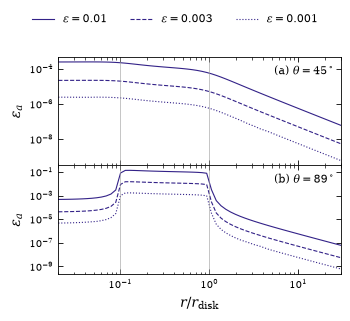

In [ ]:
SOFTENING_STYLES = dict(zip(softenings, ("-", "--", ":")))

fig, axes = new_figure(PAPER_WIDTH, height=80, nrows=2, sharex=True)
for ax, tag, theta in zip(axes, "ab", rays):
    for eps, ls in SOFTENING_STYLES.items():
        ax.plot(r_ray / R_DISK, field[theta, eps], color=COLORS[0], ls=ls, label=rf"$\epsilon={eps:g}$")
    for edge in (0.1, 1):
        ax.axvline(edge, color="0.6", lw=0.4)
    ax.text(0.98, 0.92, rf"({tag}) $\theta={theta}^\circ$", transform=ax.transAxes, ha="right", va="top")
    ax.set(ylabel=r"$\varepsilon_a$", yscale="log")
axes[-1].set(xlabel=r"$r/r_{\rm disk}$", xscale="log", xlim=(r_ray.min() / R_DISK, r_ray.max() / R_DISK))
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside upper center", ncols=3,
           frameon=False, borderpad=0.8)

glue_panels(fig)
save_paper_figure(fig, 'thin-disk', 'disk-field')
plt.show()

Reading the figure (grey lines: $r_{\rm min}$ and $r_{\rm max}$):

* Relatipy converges to Foschi's quadrature as the softening goes to zero: each step of $\epsilon$ ($\times0.3$) lowers $\varepsilon_a$ by about $10$, i.e. $\varepsilon_a\propto\epsilon^2$
* (a) away from the plane, $\varepsilon_a\lesssim2.5\times10^{-4}$ at the default $\epsilon$
* (b) just above the disk, inside its radial range, softening is an order-one change ($\varepsilon_a\sim0.1$ at $\epsilon=10^{-2}$): there Relatipy is a different (thick) disk, as intended; it still converges as $\epsilon^2$
* beyond $r_{\rm disk}$ the difference falls with $r$ on both rays

### 5.2. Pericentre precession in the disk plane

Lagrange's equation for the longitude of pericentre ([Tomaselli & Caputo 2025](https://arxiv.org/abs/2509.03568), eqs. 10 and 11):

$$\dot\varpi=-\frac{\sqrt{1-e^2}}{\sqrt{Ma}\,e}\frac{\partial\langle V\rangle}{\partial e}$$

$$\langle V\rangle=\frac1T\int_0^TV(r(t))\,dt$$

* "Equation (10) holds for spherically symmetric potentials and for equatorial orbits in axisymmetric potentials" (same paper, §III.A): here an orbit in the plane of the disk
* $V$ grows outwards, $dV/dr=M(r)/r^2$ (their Appendix A): the sign of $\Phi_{\rm disk}$ below
* units $G=c=1$; per orbit, $\Delta\varpi=\dot\varpi\,T$ with the Keplerian period $T=2\pi\sqrt{a^3/M}$

Orbit-averaged potential of the softened disk ([Piran et al. 2026](https://arxiv.org/abs/2607.24931), eqs. 10 and 11):

$$\langle\Phi_{\rm disk}\rangle=-G\int_{r_{\rm in}}^{r_{\rm out}}2\pi\Sigma(r')\,r'\,\langle\Delta^{-1}\rangle_t\,dr'$$

$$\langle\Delta^{-1}\rangle_t=\frac{\oint\Delta^{-1}(r,r',f)\,r^2\,df}{\oint r^2\,df}$$

* "the Kepler-time-weighted, azimuthally averaged inverse distance between the star at orbital phase $f$ and a disk ring at radius $r'$, with $\Delta^2=|\mathbf r-\mathbf r'|^2+H^2$ softened by the disk scale height $H=0.01\,r'$" (same paper, Sect. 4): Relatipy's default softening
* $\Sigma$: Foschi eq. 13 normalised with eq. 16 (5.1)
* average of $\Delta^{-1}$ over the azimuth of one ring: the ring potential of Foschi et al. (eq. 7) per unit $GM_{\rm ring}$,

$$U_{\rm ring}=\frac{2GM_{\rm ring}}{\pi p}K(k),\qquad k=\frac{4Rd}{p^2}$$

  whose $p$ (eq. 6) holds the height only as $z^2$; Piran's $\Delta^2$ adds $H^2$ to it, so here $p^2=(d+R)^2+z^2+H^2$. This substitution is ours, not written in either paper
* the time average: midpoint rule in $f$ with weight $r^2$; $r'$: Gauss–Legendre panels refined towards $r'=d$

In [ ]:
GAUSS_NODES, GAUSS_WEIGHTS = np.polynomial.legendre.leggauss(16)


def ring_inverse_distance(R, d, z, eps):
    """Average of 1/Delta over a ring of radius R: Foschi eq. 7 over G M_ring, with z^2 -> z^2 + H^2 and H = eps R."""
    p = np.sqrt((d + R)**2 + z**2 + (eps * R)**2)
    return 2 * ellipk(4 * R * d / p**2) / (np.pi * p)


def disk_potential(d, z, M_disk, r_in, r_out, gamma, eps):
    """Phi_disk (G = M = 1) at points (d, z) [M]: integrand of Piran eq. 10 without the time average.

    Sigma from Foschi eqs. 13 and 16; r' by 16-point Gauss-Legendre panels, refined geometrically towards r' = d.
    """
    B = M_disk * (gamma - 2) / (2*np.pi * (r_in**(2 - gamma) - r_out**(2 - gamma)))
    phi = np.empty_like(d)
    for j, (d_j, z_j) in enumerate(zip(d, z)):
        edges = [r_in, r_out, *np.geomspace(max(r_in, 1e-6 * r_out), r_out, 60)]
        if r_in < d_j < r_out:
            width = np.hypot(z_j, eps * d_j) / 4
            steps = np.geomspace(width, max(d_j - r_in, r_out - d_j), 40)
            edges += [d_j, *(d_j - steps), *(d_j + steps)]
        edges = np.unique(np.clip(edges, r_in, r_out))
        half, mid = np.diff(edges)[:, None] / 2, (edges[1:] + edges[:-1])[:, None] / 2
        R = (mid + half * GAUSS_NODES).ravel()
        weight = (half * GAUSS_WEIGHTS).ravel()
        phi[j] = -np.sum(weight * 2*np.pi * B * R**(1 - gamma) * ring_inverse_distance(R, d_j, z_j, eps))
    return phi


def orbit_average(a, e, inc, omega, n_f=2000, **shape):
    """<Phi_disk>: Piran eqs. 10 and 11, Kepler weight r^2 df, midpoint rule in the true anomaly f."""
    f = (np.arange(n_f) + 0.5) * 2*np.pi / n_f
    r = a * (1 - e**2) / (1 + e * np.cos(f))
    z = r * np.sin(inc) * np.sin(omega + f)
    phi = disk_potential(np.sqrt(r**2 - z**2), z, **shape)
    return np.sum(phi * r**2) / np.sum(r**2)


def lagrange_advance(a, e, shape, de=1e-4):
    """Delta varpi per orbit [rad]: Tomaselli & Caputo eq. 10 times T, <V> = <Phi_disk> at i = 0."""
    slope = (orbit_average(a, e + de, 0.0, 0.0, **shape) - orbit_average(a, e - de, 0.0, 0.0, **shape)) / (2 * de)
    return -np.sqrt(1 - e**2) / (np.sqrt(a) * e) * slope * 2*np.pi * a**1.5

Measured advance, for an orbit in the disk plane with the semi-major axis of S2 ($a=24\,100\,M$) and $0.1\le e\le0.95$:

* `pericentre_azimuths`: pericentres located on a coarse grid ($400$ samples per orbit), then resampled with $401$ points across each one; quadratic fit of $r(t)$ for the time of the minimum and cubic fit of the azimuth, both over $7$ samples
* `disk_advance`: advance per orbit with the fiducial disk minus the advance without it, same initial state, mean over $3$ orbits; the Schwarzschild advance cancels
* $\varepsilon=|\Delta\varpi_{\rm Relatipy}/\Delta\varpi_{\rm Lagrange}-1|$

In [ ]:
def pericentre_azimuths(state, a, n_orbits, disk=None):
    """Unwrapped azimuth [rad] of every pericentre of an orbit in the disk plane."""
    period = 2*np.pi * a**1.5
    t = np.linspace(0, n_orbits, 400 * n_orbits + 1) * period
    r = np.hypot(*disk_positions(state, t, disk=disk)[:, :2].T)
    minima = np.where((r[1:-1] < r[:-2]) & (r[1:-1] <= r[2:]))[0] + 1
    fine = np.stack([np.linspace(t[i - 1], t[i + 1], 401) for i in minima])
    x, y, _ = disk_positions(state, fine.ravel(), disk=disk).reshape(minima.size, 401, 3).transpose(2, 0, 1)
    azimuths = []
    for t_k, x_k, y_k in zip(fine, x, y):
        j = np.clip(np.argmin(np.hypot(x_k, y_k)), 3, 397)
        s = slice(j - 3, j + 4)
        dt = t_k[s] - t_k[j]
        c = np.polyfit(dt, np.hypot(x_k[s], y_k[s]), 2)
        azimuths.append(np.polyval(np.polyfit(dt, np.unwrap(np.arctan2(y_k[s], x_k[s])), 3), -c[1] / (2 * c[0])))
    return np.unwrap(azimuths)


def disk_advance(a, e, disk=FIDUCIAL, n_orbits=3):
    """Pericentre advance per orbit [rad] caused by a disk: with it minus without it, same start."""
    state = initial_state(a, e, 0.0, 0.0)
    with_disk, without = (np.mean(np.diff(pericentre_azimuths(state, a, n_orbits, d))) for d in (disk, None))
    return with_disk - without


a_apsidal = STARS["S2"]["a"]
e_apsidal = np.linspace(0.1, 0.95, 12)
e_lagrange = np.linspace(0.05, 0.96, 60)
apsidal = Table(rows=[
    dict(
        e=e,
        relatipy=disk_advance(a_apsidal, e),
        lagrange=lagrange_advance(a_apsidal, e, FIDUCIAL_SHAPE),
    )
    for e in e_apsidal
])
apsidal["rel_error"] = np.abs(apsidal["relatipy"] / apsidal["lagrange"] - 1)
lagrange_curve = np.array([lagrange_advance(a_apsidal, e, FIDUCIAL_SHAPE) for e in e_lagrange])

Figure: top, advance per orbit caused by the disk, Lagrange equation (line) and Relatipy (circles); bottom, relative difference. Grey line: $e$ at which the apocentre $a(1+e)$ reaches the outer edge of the disk.

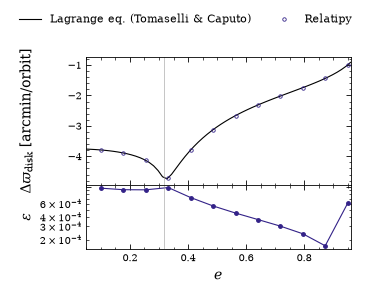

In [ ]:
fig, (ax_w, ax_e) = new_figure(PAPER_WIDTH, height=73, nrows=2, sharex=True, height_ratios=(2, 1))

ax_w.plot(e_lagrange, np.degrees(lagrange_curve) * 60, color="k", label="Lagrange eq. (Tomaselli & Caputo)")
ax_w.plot(apsidal["e"], np.degrees(apsidal["relatipy"]) * 60, "o", color=COLORS[0], ms=2.5, mfc="none", mew=0.6,
          label="Relatipy")
ax_e.plot(apsidal["e"], apsidal["rel_error"], "o-", color=COLORS[0], ms=2.5, lw=0.8)
for ax in (ax_w, ax_e):
    ax.axvline(R_DISK / a_apsidal - 1, color="0.6", lw=0.4)

ax_w.set(ylabel=r"$\Delta\varpi_{\rm disk}$ [arcmin/orbit]")
ax_e.set(xlabel=r"$e$", ylabel=r"$\varepsilon$", yscale="log", xlim=(e_lagrange.min(), e_lagrange.max()))
fig.legend(*ax_w.get_legend_handles_labels(), loc="outside upper center", ncols=2,
           frameon=False, borderpad=0.8)

glue_panels(fig)
save_paper_figure(fig, 'thin-disk', 'disk-apsidal')
plt.show()

The first-order theory is linear in $M_{\rm disk}$. Relative difference for a ten times lighter disk at three eccentricities:

In [ ]:
light = FIDUCIAL.with_parameters(disk_mass=1e2 * u.Msun)
light_shape = dict(FIDUCIAL_SHAPE, M_disk=FIDUCIAL_SHAPE["M_disk"] / 10)
Table(rows=[
    dict(
        e=e,
        rel_error_1e3=np.abs(disk_advance(a_apsidal, e) / lagrange_advance(a_apsidal, e, FIDUCIAL_SHAPE) - 1),
        rel_error_1e2=np.abs(disk_advance(a_apsidal, e, light) / lagrange_advance(a_apsidal, e, light_shape) - 1),
    )
    for e in (0.1, 0.64, 0.95)
])

e,rel_error_1e3,rel_error_1e2
float64,float64,float64
0.1,0.0009638922010269946,3.097986816347209e-05
0.64,0.00037061859061937596,1.034445567871245e-06
0.95,0.0006068499315801112,0.003088637300744712


Reading:

* Relatipy follows the Lagrange result over the whole range, including the maximum where the apocentre reaches the edge of the disk; $\varepsilon\lesssim10^{-3}$
* at low and moderate $e$, the difference shrinks by $\gtrsim10$ with a ten times lighter disk: it is second order in $M_{\rm disk}/M_{\rm BH}$, absent from the first-order theory
* at $e=0.95$ ($p=2350\,M$) the lighter disk does worse: its advance, $\sim3\times10^{-6}$ rad per orbit, approaches the $\sim10^{-8}$ rad floor of the pericentre measurement

### 5.3. Nodal precession

Secular precession of the node and its Lense–Thirring counterpart, from [Piran et al. 2026](https://arxiv.org/abs/2607.24931). Elements are measured at every apocentre, where the orbit plane is quiet (`apocentre_elements`):

* orbit pole: $\mathbf r(t_1)\times\mathbf r(t_2)$ at $t_{1,2}=t_{\rm apo}\mp0.05\,T$, two points of the same plane
* node $\Omega$ about the reference normal $\hat z$ (disk normal, or spin in 5.3.1), inclination $i$, and argument of pericentre $\omega$ from the apocentre direction, located with a quadratic fit of $r(t)$ over $1001$ samples
* the advance per orbit is the difference between consecutive apocentres; $i$ and $\omega$ of that orbit are the means of both ends

In [ ]:
def apocentre_elements(state, a, n_orbits, **kwargs):
    """Pole, inclination, node and argument of pericentre [rad] at every apocentre after the start, disk frame."""
    period = 2*np.pi * a**1.5
    t = np.linspace(0, n_orbits + 0.5, 100 * n_orbits + 51) * period
    r = np.linalg.norm(disk_positions(state, t, **kwargs), axis=1)
    peaks = np.where((r[1:-1] > r[:-2]) & (r[1:-1] >= r[2:]))[0] + 1
    window = np.linspace(-0.05, 0.05, 1001) * period
    x = disk_positions(state, np.concatenate([t[i] + window for i in peaks]), **kwargs).reshape(peaks.size, -1, 3)

    pole = np.cross(x[:, 0], x[:, -1])
    pole /= np.linalg.norm(pole, axis=1)[:, None]
    node = np.stack([-pole[:, 1], pole[:, 0], 0 * pole[:, 0]], axis=1)
    node /= np.linalg.norm(node, axis=1)[:, None]
    pericentre = []
    for x_k in x:
        j = np.clip(np.argmax(np.linalg.norm(x_k, axis=1)), 5, x_k.shape[0] - 6)
        s = slice(j - 5, j + 6)
        c = np.polyfit(window[s], np.linalg.norm(x_k[s], axis=1), 2)
        apocentre = [np.polyval(np.polyfit(window[s], x_k[s, i], 3), -c[1] / (2 * c[0])) for i in range(3)]
        pericentre.append(-np.array(apocentre) / np.linalg.norm(apocentre))
    pericentre = np.array(pericentre)
    return dict(
        inc=np.arccos(pole[:, 2]),
        Omega=np.unwrap(np.arctan2(pole[:, 0], -pole[:, 1])),
        omega=np.unwrap(np.arctan2(
            np.sum(pericentre * np.cross(pole, node), axis=1), np.sum(pericentre * node, axis=1))),
    )


def per_orbit(elements):
    """Node advance per orbit [rad] between consecutive apocentres, with the mean inclination and argument of pericentre."""
    return dict(
        dOmega=np.diff(elements["Omega"]),
        inc=(elements["inc"][1:] + elements["inc"][:-1]) / 2,
        omega=(elements["omega"][1:] + elements["omega"][:-1]) / 2,
    )

#### 5.3.1. Lense–Thirring

LT nodal rate per orbit ([Piran et al. 2026](https://arxiv.org/abs/2607.24931), eq. 4):

$$\Delta\Omega_{\rm LT}=\frac{4\pi\chi\,\sin\beta\sin\lambda}{(1-e^2)^{3/2}\,\sin i}\left(\frac{r_g}{a}\right)^{3/2}=\frac{4\pi\chi\,\sin\beta\sin\lambda}{(1+e)^{3/2}\,\sin i}\left(\frac{r_g}{r_p}\right)^{3/2}$$

* $i$: inclination to the reference plane; $\beta$: angle between spin and orbital angular momentum; $\lambda$: azimuth of the spin projection on the orbital plane, from the ascending node
* "When the reference plane is the black hole's equatorial plane, $\sin\beta\sin\lambda=\sin i$ and the familiar frame-independent rate is recovered" (same section). With the node measured about the spin:

$$\Delta\Omega_{\rm LT}=\frac{4\pi\chi}{(1-e^2)^{3/2}}\left(\frac{r_g}{a}\right)^{3/2}$$

* with $p=a(1-e^2)$ it depends on the orbit only through $(r_g/p)^{3/2}$
* reference values (their Table 1 footnote, $\chi=1$): $9.6\times10^{-4}$ (S301) and $3.3\times10^{-5}$ rad/orbit (S2)

Measurement: no disk, $\chi=1$, spin along $\hat z$, $i=88^\circ$ (nearly polar, so the orbit stays off the coordinate poles and the spin-quadrupole node term, which goes with $\cos i$, is small), $\omega=45^\circ$; mean over $2$ orbits; eccentricities of S301 and S2, $300\le p\le3\times10^4\,M$.

In [ ]:
def lense_thirring_node(a, e, chi):
    """Delta Omega_LT per orbit [rad], node about the spin: Piran et al. eq. 4 with sin(beta) sin(lambda) = sin(i)."""
    return 4*np.pi * chi / (1 - e**2)**1.5 * a**-1.5


CHI_LT = 1.0
INC_LT = np.radians(88)
p_lt = np.geomspace(300, 3e4, 10)
lense_thirring = Table(rows=[
    dict(
        star=star,
        e=orbit["e"],
        p=p,
        relatipy=np.mean(per_orbit(apocentre_elements(
            initial_state(p / (1 - orbit["e"]**2), orbit["e"], INC_LT, np.pi/4),
            p / (1 - orbit["e"]**2), 3, chi=CHI_LT))["dOmega"]),
        piran=lense_thirring_node(p / (1 - orbit["e"]**2), orbit["e"], CHI_LT),
    )
    for star, orbit in STARS.items()
    for p in p_lt
])
lense_thirring["rel_error"] = np.abs(lense_thirring["relatipy"] / lense_thirring["piran"] - 1)

Table(rows=[
    dict(
        star=star,
        piran_table_1=LT,
        eq_4=lense_thirring_node(STARS[star]["a"], STARS[star]["e"], 1.0),
        relatipy=np.mean(per_orbit(apocentre_elements(
            initial_state(STARS[star]["a"], STARS[star]["e"], INC_LT, np.pi/4), STARS[star]["a"], 3, chi=1.0))["dOmega"]),
    )
    for star, LT in (("S301", 9.6e-4), ("S2", 3.3e-5))
])

star,piran_table_1,eq_4,relatipy
str4,float64,float64,float64
S301,0.00096,0.0009599442225237192,0.0009770702704884444
S2,3.3e-05,3.303603409703946e-05,3.308378392552621e-05


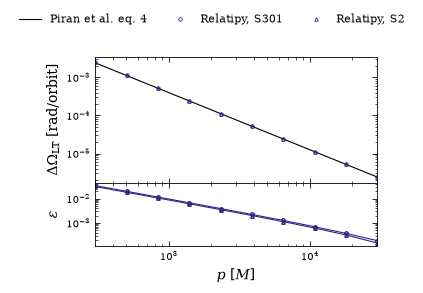

In [ ]:
ECCENTRICITY_MARKERS = dict(S301="o", S2="^")

fig, (ax_w, ax_e) = new_figure(PAPER_WIDTH, height=73, nrows=2, sharex=True, height_ratios=(2, 1))
p_fine = np.geomspace(p_lt.min(), p_lt.max(), 200)
ax_w.plot(p_fine, lense_thirring_node(p_fine, 0.0, CHI_LT), color="k", label="Piran et al. eq. 4")
for star, marker in ECCENTRICITY_MARKERS.items():
    rows = lense_thirring[lense_thirring["star"] == star]
    ax_w.plot(rows["p"], rows["relatipy"], marker, color=COLORS[0], ms=2.5, mfc="none", mew=0.6,
              label=f"Relatipy, {star}")
    ax_e.plot(rows["p"], rows["rel_error"], marker + "-", color=COLORS[0], ms=2.5, mfc="none", lw=0.8)

ax_w.set(ylabel=r"$\Delta\Omega_{\rm LT}$ [rad/orbit]", yscale="log")
ax_e.set(xlabel=r"$p$ [$M$]", ylabel=r"$\varepsilon$", xscale="log", yscale="log",
         xlim=(p_lt.min(), p_lt.max()))
fig.legend(*ax_w.get_legend_handles_labels(), loc="outside upper center", ncols=3,
           frameon=False, borderpad=0.8)

glue_panels(fig)
save_paper_figure(fig, 'thin-disk', 'lense-thirring-node')
plt.show()

Reading:

* top: both eccentricities fall on the single curve $\propto p^{-3/2}$ of eq. 4
* bottom: the difference falls as $1/p$, from $3\%$ at $p=300\,M$ to $2\times10^{-4}$ at $3\times10^4\,M$: the next post-Newtonian order, which eq. 4 leaves out
* at the elements of S301 and S2 (table above), eq. 4 gives the values quoted by Piran et al.; Relatipy is $1.8\%$ (S301) and $0.14\%$ (S2) higher, the $1/p$ term of the bottom panel

#### 5.3.2. Disk

Gauss planetary equation for the node ([Piran et al. 2026](https://arxiv.org/abs/2607.24931), eq. 1):

$$\frac{d\Omega}{dt}=-\frac{1}{h\sin i}\frac{\partial\langle\Phi_{\rm disk}\rangle}{\partial i}$$

* "$\Omega$ is the longitude of the ascending node, $i$ the inclination, and $\omega$ the argument of pericenter, all measured relative to the disk plane"; "$h=\sqrt{GM_{\rm BH}\,a(1-e^2)}$ is the specific angular momentum"
* $\langle\Phi_{\rm disk}\rangle$: eqs. 10 and 11 (5.2), now with the orbit inclined: $z=r\sin i\sin(\omega+f)$
* "The derivative $\partial\langle\Phi_{\rm disk}\rangle/\partial i$ was evaluated by a centred finite difference with step $\delta i=0.3^\circ$" (Sect. 4): the same here
* per orbit: $\Delta\Omega=\dot\Omega\,T$; the reference is evaluated at the measured $i$ and $\omega$ of each orbit
* for $\chi=0$ the disk is the only source of nodal precession; the Schwarzschild advance of $\omega$ ($1.95^\circ$ per orbit for S301, Piran et al. Sect. 6) moves the geometry while the node turns

In [ ]:
def disk_node(a, e, inc, omega, shape, di=np.radians(0.3)):
    """Delta Omega_disk per orbit [rad]: Piran et al. eq. 1 times T, centred difference in i with their step."""
    slope = (orbit_average(a, e, inc + di, omega, **shape) - orbit_average(a, e, inc - di, omega, **shape)) / (2 * di)
    h = np.sqrt(a * (1 - e**2))
    return -slope / (h * np.sin(inc)) * 2*np.pi * a**1.5


def first_orbit_node(a, e, inc, omega, disk, shape):
    """Relatipy node advance over the first measured orbit, and eq. 1 at that orbit's mean i and omega."""
    orbit = per_orbit(apocentre_elements(initial_state(a, e, inc, omega), a, 2, disk=disk))
    return dict(
        relatipy=orbit["dOmega"][0],
        piran=disk_node(a, e, orbit["inc"][0], orbit["omega"][0], shape),
    )

Without relativity the secular rate per orbit does not change if the orbit and the disk are scaled together: $\Delta\Omega$ depends only on $M_{\rm disk}/M_{\rm BH}$, $e$, $i$, $\omega$ and $r_{\rm disk}/a$ (eqs. 1, 10 and 11 in units of $a$). Relatipy includes the black hole exactly, so its departure from eq. 1 should vanish as $r_g/p\to0$:

* S301 orbit ($e=0.9825$, $i=30^\circ$) and the fiducial disk, both scaled by $k=1$ to $64$: $p=555\,k\,M$
* $\omega=90^\circ$ (anti-nodes at pericentre and apocentre) and $\omega=0^\circ$ (anti-nodes at $r=p$, next to pericentre, where the Schwarzschild advance happens)
* $\chi=0$; the first orbit after the starting apocentre

In [ ]:
scales = np.geomspace(1, 64, 7)
disk_scaling = Table(rows=[
    dict(
        omega=omega,
        p=STARS["S301"]["a"] * k * (1 - STARS["S301"]["e"]**2),
        **first_orbit_node(
            STARS["S301"]["a"] * k, STARS["S301"]["e"], np.radians(30), np.radians(omega),
            rp.ThinDisk(mass=1e3 * u.Msun, r_out=R_DISK * k * LENGTH, slope=-1.0),
            dict(FIDUCIAL_SHAPE, r_out=R_DISK * k),
        ),
    )
    for omega in (90, 0)
    for k in scales
])
disk_scaling["rel_error"] = np.abs(disk_scaling["relatipy"] / disk_scaling["piran"] - 1)

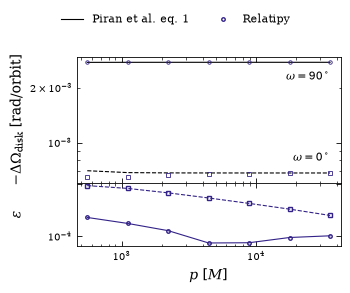

In [ ]:
OMEGA_STYLES = {
    90: dict(ls="-", marker="o", shift=1 / 1.12, va="top"),     # label below its line
    0: dict(ls="--", marker="s", shift=1.12, va="bottom"),     # label above its line
}

fig, (ax_w, ax_e) = new_figure(PAPER_WIDTH, height=73, nrows=2, sharex=True, height_ratios=(2, 1))
for omega, style in OMEGA_STYLES.items():
    rows = disk_scaling[disk_scaling["omega"] == omega]
    ax_w.plot(rows["p"], -rows["piran"], color="k", ls=style["ls"], lw=0.8)
    ax_w.plot(rows["p"], -rows["relatipy"], style["marker"], color=COLORS[0], ms=2.5, mfc="none", mew=0.6)
    ax_w.text(rows["p"].max(), -rows["piran"][-1] * style["shift"], rf"$\omega={omega}^\circ$",
              ha="right", va=style["va"])
    ax_e.plot(rows["p"], rows["rel_error"], style["marker"], color=COLORS[0], ls=style["ls"], ms=2.5,
              mfc="none", lw=0.8)
ax_w.plot([], [], color="k", label="Piran et al. eq. 1")
ax_w.plot([], [], "o", color=COLORS[0], ms=2.5, mfc="none", label="Relatipy")

ax_w.set(ylabel=r"$-\Delta\Omega_{\rm disk}$ [rad/orbit]", yscale="log")
ax_e.set(xlabel=r"$p$ [$M$]", ylabel=r"$\varepsilon$", xscale="log", yscale="log",
         xlim=(disk_scaling["p"].min() / 1.2, disk_scaling["p"].max() * 1.2))
fig.legend(*ax_w.get_legend_handles_labels(), loc="outside upper center", ncols=2,
           frameon=False, borderpad=0.8)

glue_panels(fig)
save_paper_figure(fig, 'thin-disk', 'disk-node')
plt.show()

Reading:

* top: Relatipy reproduces the secular rate of eq. 1 for both geometries; $\omega=0^\circ$ precesses about four times slower than $\omega=90^\circ$, as in Table 1 of Piran et al.
* bottom: for $\omega=0^\circ$ the difference is $\sim8\%$ at the true size of S301 ($p=555\,M$) and falls as $r_g/p$: it is the coupling of the disk torque with the relativistic motion near pericentre, where this geometry collects its torque. Eq. 1 is Newtonian and leaves it out
* for $\omega=90^\circ$ the torque is collected near apocentre: the difference is $\sim10^{-3}$ at $p=555\,M$ and levels off at $\sim10^{-4}$, the size of second-order disk terms ($M_{\rm disk}/M_{\rm BH}=2.3\times10^{-4}$)

Table 1 of Piran et al., with Relatipy (first orbit, true sizes of S301 and S2, $\chi=0$):

* $|\Delta\Omega_{\rm disk}/\Delta\Omega_{\rm LT}|$ with their LT reference values ($9.6\times10^{-4}$, $3.3\times10^{-5}$ rad/orbit) times $1/\sin i$, as in their Table 1 footnote
* `eq_1`: eq. 1 evaluated here at the initial elements, the configuration of their table; `relatipy`: Relatipy's first orbit
* last two columns: ratio of the disk precession of S2 to that of S301

In [ ]:
PIRAN_TABLE_1 = [    # Piran et al., Table 1: i, omega [deg], |dOmega_disk/dOmega_LT| for S301 and S2, S2/S301
    (10, 0, 0.41, 13, 1.0),
    (10, 90, 2.5, 19, 0.26),
    (30, 0, 0.36, 8.9, 0.85),
    (30, 90, 1.4, 14, 0.34),
    (60, 0, 0.19, 4.2, 0.75),
    (60, 90, 0.61, 6.6, 0.37),
]
LT_REFERENCE = dict(S301=9.6e-4, S2=3.3e-5)    # Piran et al., Table 1 footnote [rad/orbit]

rows = []
for inc, omega, s301, s2, s2_over_s301 in PIRAN_TABLE_1:
    eq_1, library = {}, {}
    for star, orbit in STARS.items():
        eq_1[star] = disk_node(orbit["a"], orbit["e"], np.radians(inc), np.radians(omega), FIDUCIAL_SHAPE)
        library[star] = per_orbit(apocentre_elements(
            initial_state(orbit["a"], orbit["e"], np.radians(inc), np.radians(omega)), orbit["a"], 2,
            disk=FIDUCIAL))["dOmega"][0]
    ratio = lambda node, star: abs(node[star]) * np.sin(np.radians(inc)) / LT_REFERENCE[star]
    rows.append(dict(
        i=inc,
        omega=omega,
        S301_piran=s301,
        S301_eq_1=ratio(eq_1, "S301"),
        S301_relatipy=ratio(library, "S301"),
        S2_piran=s2,
        S2_eq_1=ratio(eq_1, "S2"),
        S2_relatipy=ratio(library, "S2"),
        S2_over_S301_piran=s2_over_s301,
        S2_over_S301_eq_1=eq_1["S2"] / eq_1["S301"],
        S2_over_S301_relatipy=library["S2"] / library["S301"],
    ))
piran_table = Table(rows=rows)
for name in piran_table.colnames[3:]:
    piran_table[name].format = ".3g"
piran_table

i,omega,S301_piran,S301_eq_1,S301_relatipy,S2_piran,S2_eq_1,S2_relatipy,S2_over_S301_piran,S2_over_S301_eq_1,S2_over_S301_relatipy
int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64
10,0,0.41,0.408,0.395,13,12.4,12.4,1,1.04,1.08
10,90,2.5,2.47,2.47,19,18.8,18.8,0.26,0.262,0.262
30,0,0.36,0.354,0.337,8.9,8.75,8.73,0.85,0.848,0.891
30,90,1.4,1.44,1.44,14,14,14,0.34,0.336,0.336
60,0,0.19,0.188,0.177,4.2,4.1,4.09,0.75,0.751,0.793
60,90,0.61,0.595,0.595,6.6,6.5,6.5,0.37,0.376,0.376


Reading:

* eq. 1 as evaluated here agrees with Table 1 of Piran et al. within $2.5\%$ for S301 and $1.5$–$5\%$ for S2 (here always lower for S2), and its S2/S301 ratio matches their last column to two digits. The S2 offset therefore seems to lie in the normalisation by $\Delta\Omega_{\rm LT}$ rather than in the disk torque (our inference; their inner edge and quadrature are not stated, $R_{\rm in}=0$ here)
* Relatipy agrees with eq. 1 to three digits for S2 and for S301 at $\omega=90^\circ$
* for S301 at $\omega=0^\circ$ Relatipy is $3$–$6\%$ lower than eq. 1: the relativistic coupling of the previous figure, absent from the Newtonian calculation. The same rows move the S2/S301 ratio from $\approx0.75$–$1.0$ to $0.79$–$1.08$